<a href="https://colab.research.google.com/github/adhamov8/BDA_HW-shopper-analytics/blob/main/BDA_HW1_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv("/content/shopper_sample_500_seed42.csv")

print("Строк и столбцов:", df.shape)
print("Пропущенных значений:", df.isna().sum().sum())
display(df.head())

Строк и столбцов: (500, 19)
Пропущенных значений: 0


,row_id_in_source,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,8916,3,142.500000,0,0.00,48,1052.255952,0.004348,0.013043,0.000000,0.0,Nov,1,8,6,11,Returning_Visitor,False,False
1,772,6,437.391304,2,235.55,83,2503.881781,0.002198,0.004916,2.086218,0.0,Mar,2,2,3,2,Returning_Visitor,False,True
2,12250,1,41.125000,0,0.00,126,4310.004668,0.000688,0.012823,3.451072,0.0,Nov,2,2,2,2,Returning_Visitor,False,False
3,7793,2,141.000000,0,0.00,10,606.666667,0.008333,0.026389,36.672294,0.0,Aug,2,5,7,4,Returning_Visitor,False,False
4,6601,18,608.140000,6,733.80,168,4948.398759,0.006632,0.013528,10.150644,0.0,Aug,2,2,3,1,Returning_Visitor,True,False


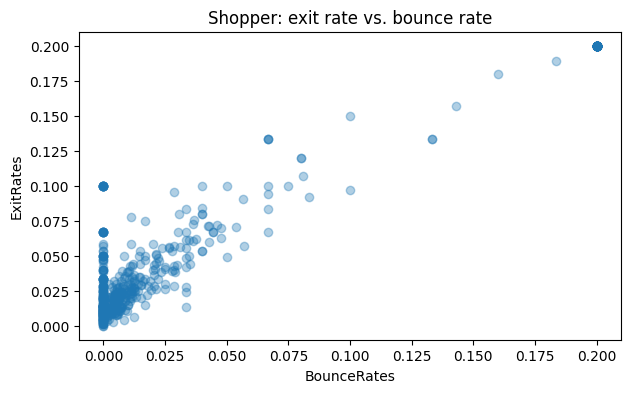

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.scatter(df["BounceRates"], df["ExitRates"], alpha=0.35)
plt.xlabel("BounceRates")
plt.ylabel("ExitRates")
plt.title("Shopper: exit rate vs. bounce rate")
plt.show()

The scatter plot shows a positive, approximately linear relationship between BounceRates and ExitRates. Most sessions have low values of both variables. At a bounce rate of zero, exit rates still vary.

In [12]:
from scipy.stats import linregress

x = df["BounceRates"]
y = df["ExitRates"]
model = linregress(x, y)

print(f"Predicted ExitRates = {model.intercept:.5f} + {model.slope:.5f} × BounceRates")
print(f"Correlation (r) = {model.rvalue:.4f}")
print(f"R² = {model.rvalue**2:.4f}")

Predicted ExitRates = 0.02176 + 0.90645 × BounceRates
Correlation (r) = 0.9303
R² = 0.8655


A one-percentage-point increase in BounceRates is associated with a 0.91-percentage-point increase in predicted ExitRates.


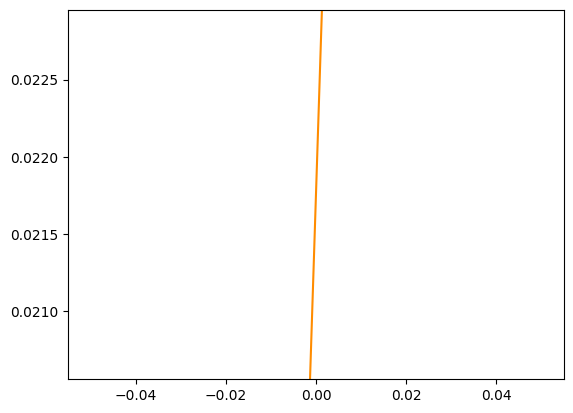

In [7]:
plt.axline((0, model.intercept), slope=model.slope, color="darkorange")

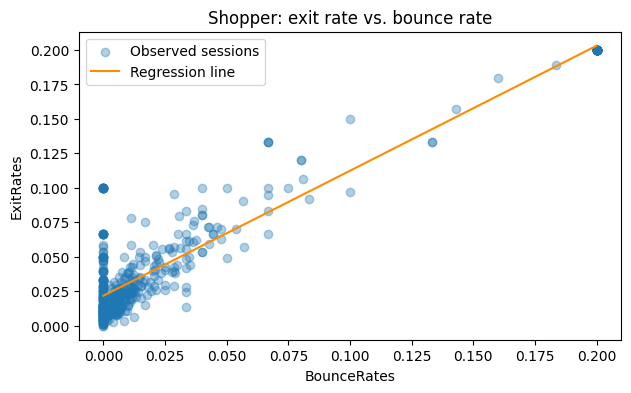

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.35, label="Observed sessions")

# Прогноз на левом и правом краях графика
x_line = [x.min(), x.max()]
y_line = [model.intercept + model.slope * value for value in x_line]
plt.plot(x_line, y_line, color="darkorange", label="Regression line")

plt.xlabel("BounceRates")
plt.ylabel("ExitRates")
plt.title("Shopper: exit rate vs. bounce rate")
plt.legend()
plt.show()

In [9]:
examples = df[["row_id_in_source", "BounceRates", "ExitRates"]].head(4).copy()

examples["Predicted_ExitRates"] = (
    model.intercept + model.slope * examples["BounceRates"]
)
examples["Error_pp"] = 100 * (
    examples["ExitRates"] - examples["Predicted_ExitRates"]
)

display(examples.round(4))

,row_id_in_source,BounceRates,ExitRates,Predicted_ExitRates,Error_pp
0,8916,0.0043,0.0130,0.0257,-1.2653
1,772,0.0022,0.0049,0.0237,-1.8832
2,12250,0.0007,0.0128,0.0224,-0.9556
3,7793,0.0083,0.0264,0.0293,-0.2920


In [11]:
pred = model.intercept + model.slope * x
abs_error = (y - pred).abs()

# При фактическом ExitRates = 0 ошибка DA не определена
valid_da = y.ne(0)
da = abs_error[valid_da] / y[valid_da].abs()
ml = abs_error / pred.abs()  # все прогнозы этой модели положительны

print(f"Zero actual exit rates: {(~valid_da).sum()}")
print(f"Mean DA error ({len(da)} sessions): {100 * da.mean():.2f}%")
print(f"Mean ML error ({len(ml)} sessions): {100 * ml.mean():.2f}%")
print(f"Mean ML error on the same {len(da)} sessions: {100 * ml[valid_da].mean():.2f}%")

Zero actual exit rates: 2
Mean DA error (498 sessions): 95.28%
Mean ML error (500 sessions): 49.42%
Mean ML error on the same 498 sessions: 49.22%


The regression explains 86.55% of the variation in ExitRates. However, predictions for individual sessions can have large relative errors, especially when the observed exit rate is close to zero. The mean DA error was 95.28% for the 498 sessions with nonzero ExitRates; it was undefined for the other two. The mean ML error was 49.42% across all 500 sessions and 49.22% on the same 498 sessions.